# Classificação de Espécies de Pinguins com Naive Bayes
**Trabalho N2 – Probabilidade e Estatística (IFCE) – Prof. Valberto Feitosa**

Versão enxuta: contém apenas as etapas pedidas no enunciado (seções 2.1 e 2.2 e salvamento do modelo).

## Checklist do enunciado

| Item pedido no documento | Onde está neste notebook |
|---|---|
| Origem da base de dados | Seção 1 |
| Quantidade de observações | Seção 1 |
| Quantidade de variáveis preditoras | Seção 1 |
| Variável-alvo | Seção 1 |
| Classes da variável-alvo | Seção 1 |
| Análise exploratória dos dados | Seção 3 |
| Estatísticas descritivas das variáveis | Seção 3.1 |
| Distribuição das classes | Seção 3.2 |
| Justificativa das variáveis usadas no modelo | Seção 4 |
| Etapas de pré-processamento explicadas | Seção 2 |
| Carregar a base de dados | Seção 1 |
| Selecionar as variáveis preditoras | Seção 4 |
| Dividir em treino e teste | Seção 5 |
| Treinar um modelo Naive Bayes | Seção 5 |
| Acurácia, Precisão, Revocação e F1-Score | Seção 6 |
| Matriz de confusão | Seção 6 |
| Salvar o modelo com joblib ou pickle | Seção 7 |

**Bibliotecas:** Pandas, NumPy, Scikit-Learn e Joblib (todas da lista do enunciado), e Matplotlib apenas para os gráficos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

## 1. Carregamento e características da base

**Origem:** Palmer Penguins – dados coletados pela Dra. Kristen Gorman na Estação Palmer (Antártica),
disponibilizados no pacote `palmerpenguins` (Horst, Hill & Gorman, 2020). O arquivo CSV é carregado do repositório
público `seaborn-data` no GitHub.

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_original = pd.read_csv(URL)

# Tradução das colunas e dos valores para o português
df_original = df_original.rename(columns={
    "species": "especie",
    "island": "ilha",
    "bill_length_mm": "comprimento_bico_mm",
    "bill_depth_mm": "profundidade_bico_mm",
    "flipper_length_mm": "comprimento_nadadeira_mm",
    "body_mass_g": "massa_corporal_g",
    "sex": "sexo",
})
df_original["especie"] = df_original["especie"].map({"Adelie": "Adélia", "Chinstrap": "Barbicha", "Gentoo": "Gentoo"})
df_original["sexo"] = df_original["sexo"].map({"MALE": "Macho", "FEMALE": "Fêmea"})

df_original.head()

,especie,ilha,comprimento_bico_mm,profundidade_bico_mm,comprimento_nadadeira_mm,massa_corporal_g,sexo
0,Adélia,Torgersen,39.1,18.7,181.0,3750.0,Macho
1,Adélia,Torgersen,39.5,17.4,186.0,3800.0,Fêmea
2,Adélia,Torgersen,40.3,18.0,195.0,3250.0,Fêmea
3,Adélia,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adélia,Torgersen,36.7,19.3,193.0,3450.0,Fêmea


In [3]:
ESPECIES = ["Adélia", "Barbicha", "Gentoo"]
NUMERICAS = ["comprimento_bico_mm", "profundidade_bico_mm", "comprimento_nadadeira_mm", "massa_corporal_g"]
preditoras = [col for col in df_original.columns if col != "especie"]

print(f"Quantidade de observações: {len(df_original)}")
print(f"Quantidade de variáveis preditoras: {len(preditoras)}  ->  {preditoras}")
print("Variável-alvo: especie")
print(f"Classes da variável-alvo: {ESPECIES}")

Quantidade de observações: 344
Quantidade de variáveis preditoras: 6  ->  ['ilha', 'comprimento_bico_mm', 'profundidade_bico_mm', 'comprimento_nadadeira_mm', 'massa_corporal_g', 'sexo']
Variável-alvo: especie
Classes da variável-alvo: ['Adélia', 'Barbicha', 'Gentoo']


## 2. Pré-processamento

### 2.1 Valores faltantes

In [4]:
df_original.isna().sum().rename("valores faltantes")

especie                      0
ilha                         0
comprimento_bico_mm          2
profundidade_bico_mm         2
comprimento_nadadeira_mm     2
massa_corporal_g             2
sexo                        11
Name: valores faltantes, dtype: int64

Duas observações não têm nenhuma medida e outras nove não têm o `sexo`. Como são poucas linhas (cerca de 3% da base),
optamos por **removê-las** em vez de preencher com valores inventados.

In [5]:
df = df_original.dropna().reset_index(drop=True)
print(f"Antes: {len(df_original)} linhas  |  Depois: {len(df)} linhas  |  Removidas: {len(df_original) - len(df)}")

Antes: 344 linhas  |  Depois: 333 linhas  |  Removidas: 11


### 2.2 Normalização
**Não foi aplicada.** O Naive Bayes Gaussiano estima a média e a variância de cada variável separadamente dentro de cada
classe, então a escala das variáveis (mm e g) não interfere no resultado.

## 3. Análise exploratória

### 3.1 Estatísticas descritivas

In [6]:
nomes_estatisticas = {"count": "contagem", "mean": "média", "std": "desvio padrão", "min": "mínimo",
                      "25%": "1º quartil", "50%": "mediana", "75%": "3º quartil", "max": "máximo"}
df[NUMERICAS].describe().rename(index=nomes_estatisticas).round(2)

,comprimento_bico_mm,profundidade_bico_mm,comprimento_nadadeira_mm,massa_corporal_g
contagem,333.00,333.00,333.00,333.00
média,43.99,17.16,200.97,4207.06
desvio padrão,5.47,1.97,14.02,805.22
mínimo,32.10,13.10,172.00,2700.00
1º quartil,39.50,15.60,190.00,3550.00
mediana,44.50,17.30,197.00,4050.00
3º quartil,48.60,18.70,213.00,4775.00
máximo,59.60,21.50,231.00,6300.00


In [7]:
# Média e desvio padrão de cada variável por espécie
por_especie = df.groupby("especie")[NUMERICAS].agg(["mean", "std"]).round(2)
por_especie.rename(columns={"mean": "média", "std": "desvio"}, level=1).loc[ESPECIES]

comprimento_bico_mm        profundidade_bico_mm         \
                       média desvio                média desvio   
especie                                                           
Adélia                 38.82   2.66                18.35   1.22   
Barbicha               48.83   3.34                18.42   1.14   
Gentoo                 47.57   3.11                15.00   0.99   

         comprimento_nadadeira_mm        massa_corporal_g          
                            média desvio            média  desvio  
especie                                                            
Adélia                     190.10   6.52          3706.16  458.62  
Barbicha                   195.82   7.13          3733.09  384.34  
Gentoo                     217.24   6.59          5092.44  501.48

In [8]:
# Variáveis categóricas: frequência por espécie
display(pd.crosstab(df["especie"], df["ilha"]).loc[ESPECIES])
display(pd.crosstab(df["especie"], df["sexo"]).loc[ESPECIES])

ilha,Biscoe,Dream,Torgersen
especie,,,
Adélia,44,55,47
Barbicha,0,68,0
Gentoo,119,0,0


sexo,Fêmea,Macho
especie,,
Adélia,73,73
Barbicha,34,34
Gentoo,58,61


### 3.2 Distribuição das classes

,quantidade,proporção (%)
especie,,
Adélia,146,43.8
Barbicha,68,20.4
Gentoo,119,35.7


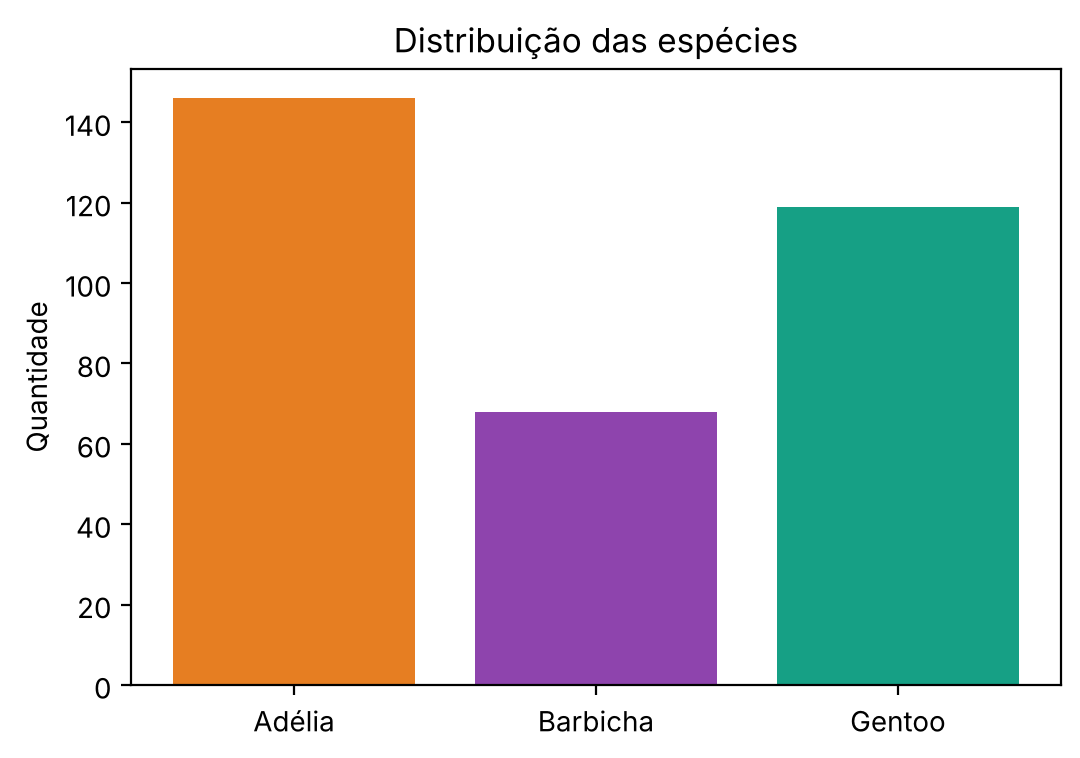

In [9]:
contagem = df["especie"].value_counts().reindex(ESPECIES)
proporcao = (contagem / len(df) * 100).round(1)
display(pd.DataFrame({"quantidade": contagem, "proporção (%)": proporcao}))

plt.figure(figsize=(6, 4))
plt.bar(contagem.index, contagem.values, color=["#E67E22", "#8E44AD", "#16A085"])
plt.title("Distribuição das espécies")
plt.ylabel("Quantidade")
plt.show()

A base é levemente desbalanceada (a Barbicha tem cerca de metade das observações da Adélia), por isso a divisão
treino/teste é feita de forma estratificada.

### 3.3 Histogramas das variáveis numéricas por espécie

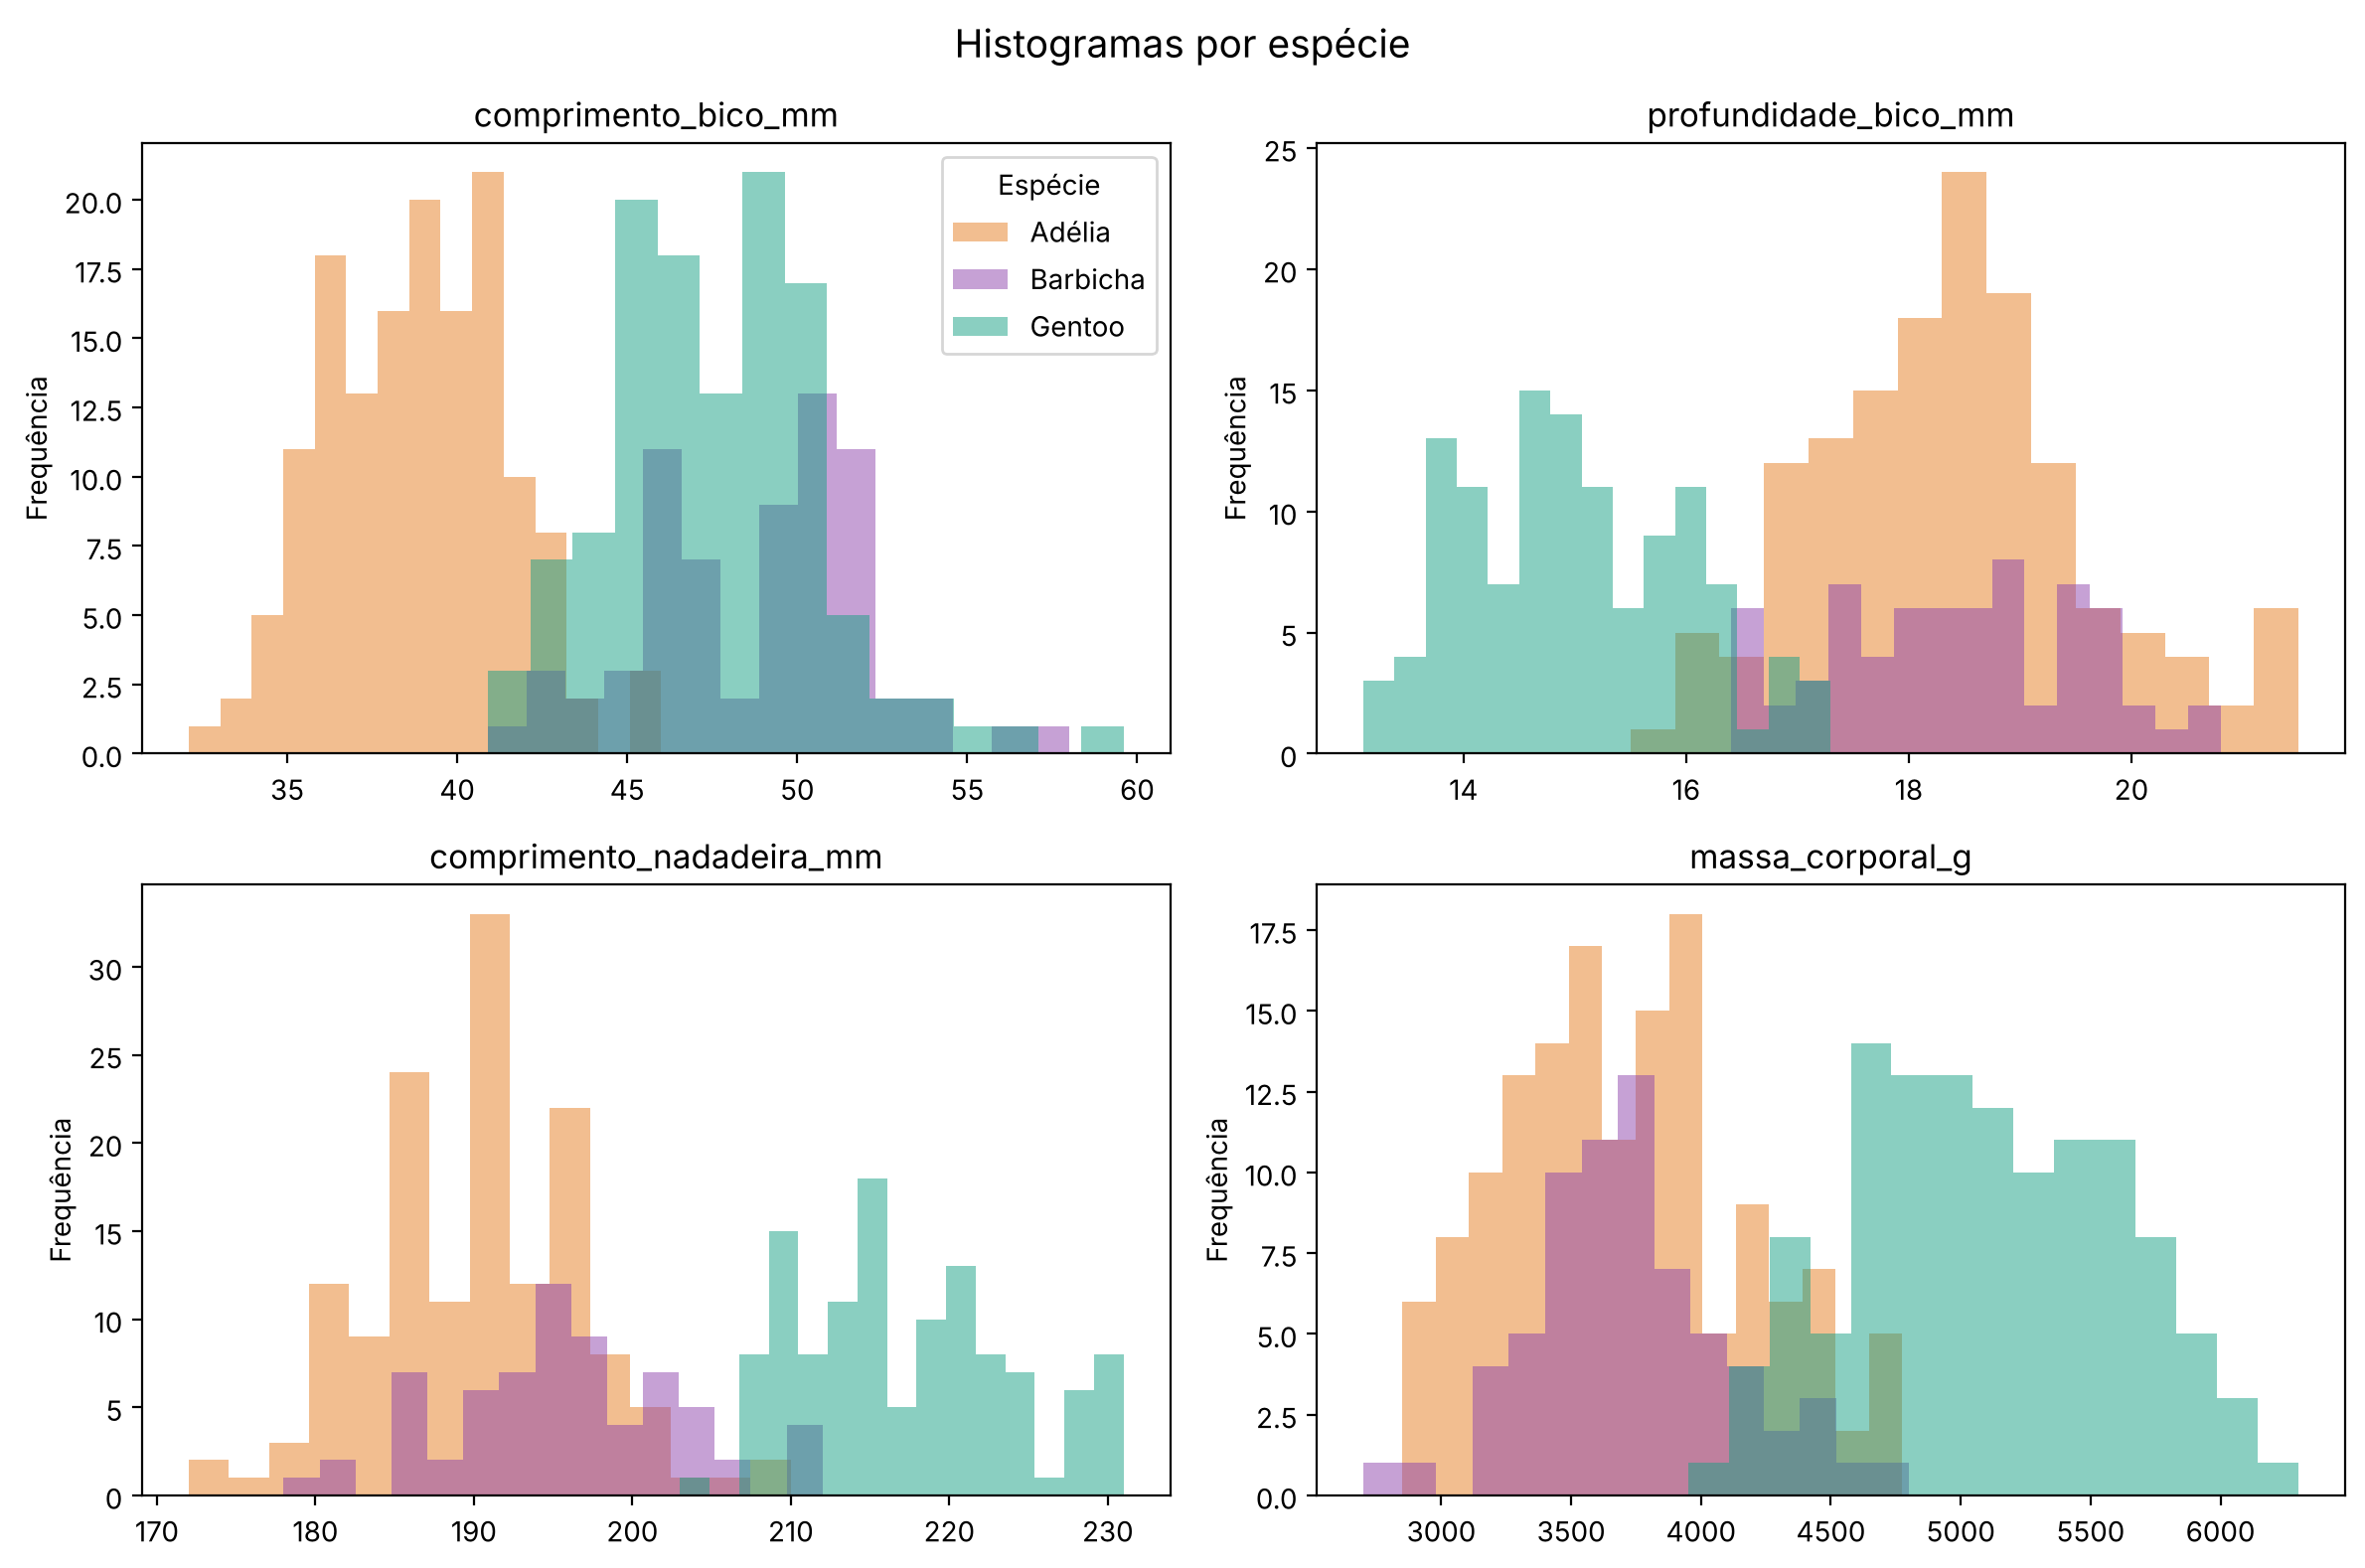

In [10]:
cores = {"Adélia": "#E67E22", "Barbicha": "#8E44AD", "Gentoo": "#16A085"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, NUMERICAS):
    for esp in ESPECIES:
        ax.hist(df.loc[df["especie"] == esp, col], bins=15, alpha=0.5, color=cores[esp], label=esp)
    ax.set_title(col)
    ax.set_ylabel("Frequência")
axes[0, 0].legend(title="Espécie")
plt.suptitle("Histogramas por espécie", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Seleção das variáveis

**Variáveis escolhidas:** `comprimento_bico_mm`, `profundidade_bico_mm` e `comprimento_nadadeira_mm`.

Justificativa, com base nas estatísticas por espécie e nos histogramas:

- **Comprimento do bico:** a Adélia tem bico bem mais curto (média de cerca de 39 mm) que a Barbicha e o Gentoo (cerca de 48 mm).
- **Profundidade do bico:** o Gentoo tem bico mais fino (cerca de 15 mm) que as outras duas espécies (cerca de 18 mm).
- **Comprimento da nadadeira:** o Gentoo tem nadadeiras bem maiores (cerca de 217 mm, contra 190 a 196 mm).
- **Massa corporal (não usada):** só separa o Gentoo, que já é separado pela nadadeira. Adélia e Barbicha têm massas
  praticamente iguais (cerca de 3700 g), então ela não acrescenta informação nova.
- **Ilha (não usada):** é uma informação de localização, não uma característica do animal. Além disso, é categórica,
  e o Naive Bayes Gaussiano supõe variáveis numéricas com distribuição normal.
- **Sexo (não usado):** a proporção de machos e fêmeas é praticamente igual nas três espécies, então ele não ajuda
  a diferenciá-las.

In [11]:
ATRIBUTOS = ["comprimento_bico_mm", "profundidade_bico_mm", "comprimento_nadadeira_mm"]
X = df[ATRIBUTOS]
y = df["especie"]

## 5. Divisão treino/teste e treinamento

75% dos dados para treino e 25% para teste. O `stratify=y` mantém a proporção das espécies nos dois conjuntos,
e o `random_state=42` garante que a divisão seja sempre a mesma.

In [12]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Treino: {len(X_treino)} observações  |  Teste: {len(X_teste)} observações")

modelo = GaussianNB()
modelo.fit(X_treino, y_treino)

Treino: 249 observações  |  Teste: 84 observações


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[109., 51., 89.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.44,0.2 ,0.36]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U8](3,)","['Adélia','Barbicha','Gentoo']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.969e-07
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['comprimento_bico_mm','profundidade_bico_mm','comprimento_nadadeira_mm']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 3)","[[ 38.72, 18.4 ,190.52], [ 48.99, 18.55,196.14], [ 47.57, 15.05,217.65]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 3)","[[ 6.1 , 1.51,43.3 ], [11.59, 1.09,53.61], [10.14, 1.01,42.32]]"


## 6. Avaliação do modelo

In [13]:
y_previsto = modelo.predict(X_teste)

pd.DataFrame({"valor": [
    accuracy_score(y_teste, y_previsto),
    precision_score(y_teste, y_previsto, average="macro"),
    recall_score(y_teste, y_previsto, average="macro"),
    f1_score(y_teste, y_previsto, average="macro"),
]}, index=["Acurácia", "Precisão", "Revocação (Recall)", "F1-Score"]).round(3)

,valor
Acurácia,0.976
Precisão,0.971
Revocação (Recall),0.971
F1-Score,0.971


Precisão, revocação e F1-Score calculados como média entre as três classes (`average="macro"`).

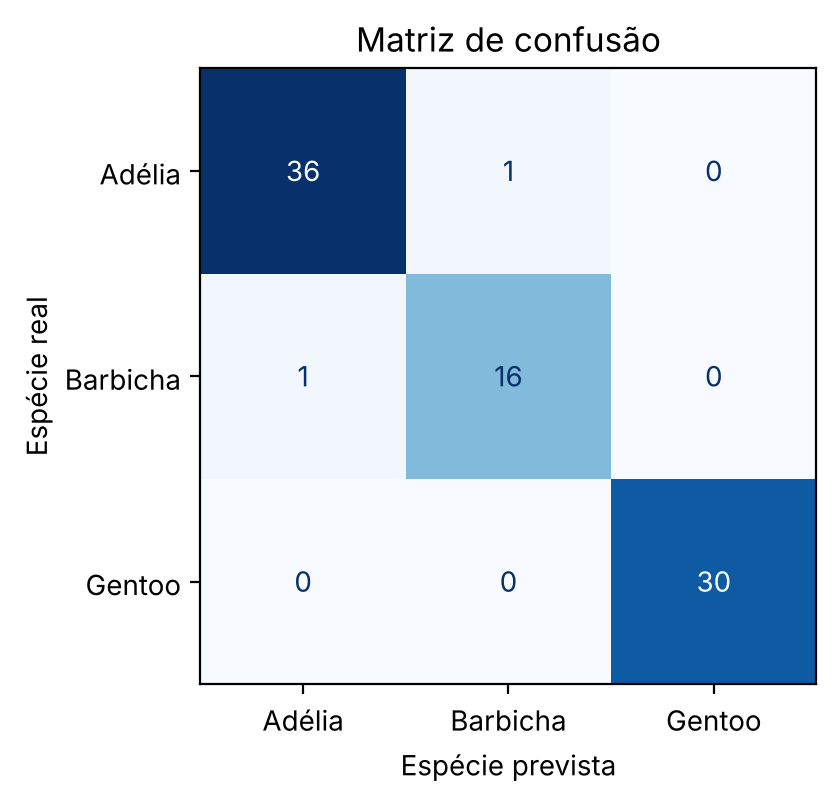

In [14]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_teste, y_previsto, labels=ESPECIES),
                       display_labels=ESPECIES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusão")
ax.set_xlabel("Espécie prevista")
ax.set_ylabel("Espécie real")
plt.show()

## 7. Salvamento do modelo

O modelo é salvo com `joblib` para ser carregado depois pela aplicação web.
Como ele foi treinado com um DataFrame, os nomes e a ordem das colunas ficam guardados em `modelo.feature_names_in_`.

In [15]:
joblib.dump(modelo, "modelo_pinguins.joblib")
print("Modelo salvo em modelo_pinguins.joblib")
print("Colunas esperadas, nesta ordem:", list(modelo.feature_names_in_))

Modelo salvo em modelo_pinguins.joblib
Colunas esperadas, nesta ordem: ['comprimento_bico_mm', 'profundidade_bico_mm', 'comprimento_nadadeira_mm']


## 8. Informações para o back-end e o front-end
*(Seção de apoio para a equipe – não é um item avaliado do enunciado.)*

### 8.1 Campos do formulário
Um campo para cada variável usada no treinamento, com as faixas observadas na base (úteis para validar a entrada).

In [16]:
rotulos = {
    "comprimento_bico_mm": "Comprimento do bico (mm)",
    "profundidade_bico_mm": "Profundidade do bico (mm)",
    "comprimento_nadadeira_mm": "Comprimento da nadadeira (mm)",
}
campos = df[ATRIBUTOS].agg(["min", "max"]).T.rename(columns={"min": "mínimo observado", "max": "máximo observado"})
campos.insert(0, "rótulo no formulário", [rotulos[a] for a in ATRIBUTOS])
campos["unidade"] = "mm"
campos

,rótulo no formulário,mínimo observado,máximo observado,unidade
comprimento_bico_mm,Comprimento do bico (mm),32.1,59.6,mm
profundidade_bico_mm,Profundidade do bico (mm),13.1,21.5,mm
comprimento_nadadeira_mm,Comprimento da nadadeira (mm),172.0,231.0,mm


### 8.2 Valores típicos de cada espécie
Médias por espécie, que podem ser usadas em botões de exemplo (“preencher com um pinguim Adélia”, etc.)
para facilitar a demonstração.

In [17]:
df.groupby("especie")[ATRIBUTOS].mean().loc[ESPECIES].round(1)

,comprimento_bico_mm,profundidade_bico_mm,comprimento_nadadeira_mm
especie,,,
Adélia,38.8,18.3,190.1
Barbicha,48.8,18.4,195.8
Gentoo,47.6,15.0,217.2


### 8.3 Como o back-end deve usar o modelo
1. Carregar o arquivo `modelo_pinguins.joblib` uma vez, quando o servidor iniciar.
2. Montar um DataFrame com **uma linha** e as colunas **com estes nomes e nesta ordem**:
   `comprimento_bico_mm`, `profundidade_bico_mm`, `comprimento_nadadeira_mm`.
3. Usar `predict` para obter a espécie e, opcionalmente, `predict_proba` para a probabilidade de cada espécie.

O modelo devolve os nomes em português: `"Adélia"`, `"Barbicha"` ou `"Gentoo"`.
A versão do scikit-learn do servidor deve ser a mesma usada aqui (mostrada abaixo).

In [18]:
import sklearn

modelo_carregado = joblib.load("modelo_pinguins.joblib")

# Exemplo de entrada, como viria do formulário
dados_formulario = {"comprimento_bico_mm": 47.5, "profundidade_bico_mm": 15.0, "comprimento_nadadeira_mm": 217}
entrada = pd.DataFrame([dados_formulario])[list(modelo_carregado.feature_names_in_)]

especie = modelo_carregado.predict(entrada)[0]
probabilidades = modelo_carregado.predict_proba(entrada)[0]

print("Espécie prevista:", especie)
for classe, p in zip(modelo_carregado.classes_, probabilidades):
    print(f"  {classe:10s} {p:.1%}")
print("\nVersão do scikit-learn:", sklearn.__version__)

Espécie prevista: Gentoo
  Adélia     0.0%
  Barbicha   0.0%
  Gentoo     100.0%

Versão do scikit-learn: 1.9.1
